In [1]:
import ler
ler.__version__

'1.0.2'

In [3]:
from ler import LeR

jyp = LeR(
    npool = 4,
)

Extracting interpolator data from package to the current working directory.

Initializing LeR class...


Initializing LensGalaxyParameterDistribution class...


Initializing OpticalDepth class

comoving_distance interpolator will be loaded from ./interpolator_json/comoving_distance/comoving_distance_0.json
angular_diameter_distance interpolator will be loaded from ./interpolator_json/angular_diameter_distance/angular_diameter_distance_0.json
angular_diameter_distance interpolator will be loaded from ./interpolator_json/angular_diameter_distance/angular_diameter_distance_0.json
differential_comoving_volume interpolator will be loaded from ./interpolator_json/differential_comoving_volume/differential_comoving_volume_0.json
using ler available velocity dispersion function : velocity_dispersion_ewoud
velocity_dispersion_ewoud interpolator will be loaded from ./interpolator_json/velocity_dispersion/velocity_dispersion_ewoud_0.json
using ler available axis_ratio function : rayleigh
rayleigh 

## Unlensed

In [5]:
unlensed_pop = jyp.unlensed_cbc_statistics()

unlensed params will be stored in ./ler_data/unlensed_param.json
removing ./ler_data/unlensed_param.json if it exists
resuming from ./ler_data/unlensed_param.json
Batch no. 1
sampling gw source params...
calculating pdet...
Batch no. 2
sampling gw source params...
calculating pdet...
saving all unlensed parameters in ./ler_data/unlensed_param.json 


In [9]:
unlensed_pop['zs']

array([1.80078498, 5.9214311 , 1.17878708, ..., 2.81543412,
       4.07820751, 1.14845906], shape=(100000,))

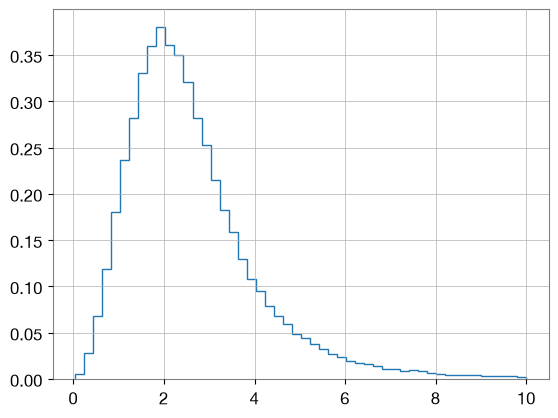

In [13]:
import matplotlib.pyplot as plt

plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0');

In [16]:
unlensed_rate, unlensed_pop_det = jyp.unlensed_rate(
    unlensed_param = unlensed_pop,
)

Using provided unlensed_param dict...
total unlensed rate (yr^-1): 359.0084941811995
number of simulated unlensed detectable events: 392
number of simulated all unlensed events: 100000
storing detectable params in ./ler_data/unlensed_param_detectable.json


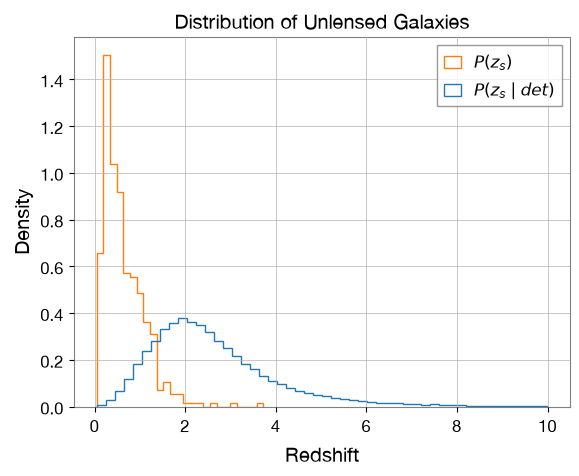

In [ ]:
plt.hist(unlensed_pop_det['zs'], bins=25, density=True, histtype='step', color='C1');
plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0');
plt.xlabel('Redshift')
plt.ylabel('Density')
plt.title('Distribution of Unlensed Galaxies')
plt.legend([r'$P(z_s)$', '$P(z_s\mid det)$'])
plt.show()

In [ ]:
from ler.utils import get_param_from_json   # 아까 저장했던 output json 파일을 불러올 수 있음

unlensed_param_det = get_param_from_json(
    json_file = './ler_data/unlensed_param_detectable.json'
)

In [ ]:
unlensed_param_det  # like this

{'zs': array([1.17706884, 1.52626788, 0.21081562, ..., 0.60228525,
        0.10751381, 0.21549486], shape=(392,)),
 'mass_1_source': array([56.74808464, 61.91298501, 10.7693642 , ..., 26.58105748,
         9.73765818, 10.12516378], shape=(392,)),
 'mass_ratio': array([0.79140964, 0.86360386, 0.77875307, ..., 0.80659255,
        0.68219283, 0.59582121], shape=(392,)),
 'mass_2_source': array([44.91098107, 53.46829259,  8.38667543, ..., 21.44008305,
         6.64296057,  6.03278733], shape=(392,)),
 'geocent_time': array([1.25577836e+09, 1.25233473e+09, 1.25585646e+09, ...,
        1.26946390e+09, 1.26503098e+09, 1.26729664e+09],
       shape=(392,)),
 'ra': array([4.4255881 , 1.52811343, 4.98811817, ..., 1.67198874,
        4.99246993, 5.00499806], shape=(392,)),
 'dec': array([-0.13577051,  0.93156875, -0.21016548, ...,  1.13220828,
         0.51606981,  0.98497668], shape=(392,)),
 'phase': array([1.31461996, 3.13983218, 4.84122962, ..., 3.56683648,
        3.49837574, 5.88166532], sh

## Lensed

In [26]:
lensed_pop = jyp.lensed_cbc_statistics()

lensed params will be stored in ./ler_data/lensed_param.json
removing ./ler_data/lensed_param.json if it exists
resuming from ./ler_data/lensed_param.json
Batch no. 1
sampling lensed params...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
Invalid sample found. Resampling 156 lensed events...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
calculating pdet...
Batch no. 2
sampling lensed params...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
Invalid sample found. Resampling 139 lensed events...
sampling lens parameters with epl_shear_sl_parameters_rvs...
computing image properties using ler's epl+shear (analytical, njit) solver...
calculating pdet...
saving all lensed parameters in ./ler_data/lensed_param.json 


In [ ]:
lensed_pop['time_delays'][0]
# column = images, row = events

array([      0.        , 2276016.78378984,              nan,
                    nan])

In [35]:
# Recover redundant parameters (like theta_E, n_images, mass_1, mass_2, luminosity_distance) for the detectable lensed events
lensed_pop = jyp.recover_redundant_parameters(lensed_pop)
lensed_pop = jyp.produce_effective_params(lensed_pop)

In [37]:
lensed_pop['effective_geocent_time'][0][1]-lensed_pop['effective_geocent_time'][0][0]

np.float64(2276016.783789873)

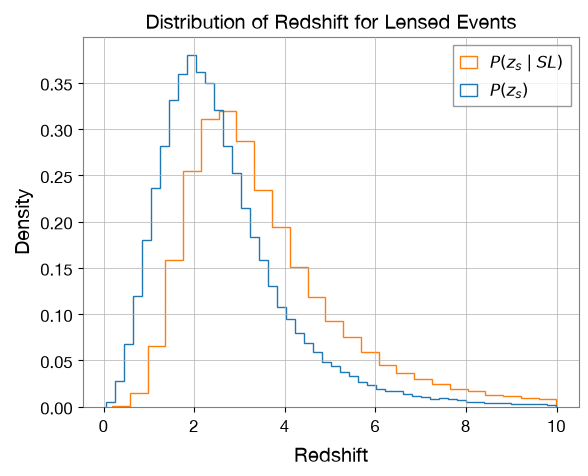

In [40]:
# plot redshift

plt.hist(lensed_pop['zs'], bins=25, density=True, histtype='step', color='C1', label=r'$P(z_s\mid SL)$');
plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0', label=r'$P(z_s)$');
plt.xlabel('Redshift');
plt.ylabel('Density');
plt.title('Distribution of Redshift for Lensed Events');
plt.legend();
plt.show();

In [41]:
lensed_rate, lensed_pop_det = jyp.lensed_rate(
    lensed_param = lensed_pop,
)

Using provided lensed_param dict...
total lensed rate (yr^-1): 0.1422831772378339
number of simulated lensed detectable events: 128
number of simulated all lensed events: 100000
storing detectable params in ./ler_data/lensed_param_detectable.json


In [42]:
jyp.rate_ratio()

unlensed_rate: 359.0084941811995
lensed_rate: 0.1422831772378339
ratio: 2523.197057801835


2523.197057801835

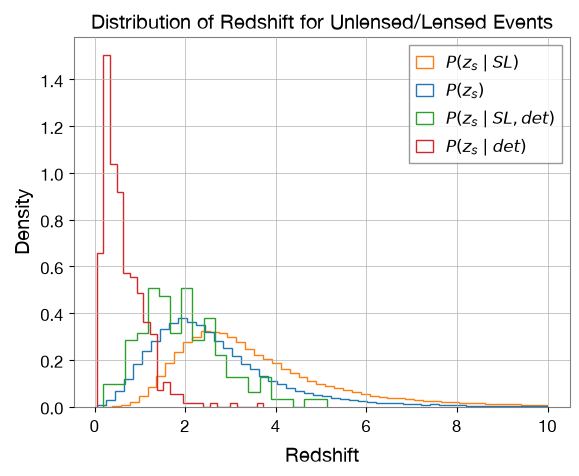

In [44]:
plt.hist(lensed_pop['zs'], bins=50, density=True, histtype='step', color='C1', label=r'$P(z_s\mid SL)$');
plt.hist(unlensed_pop['zs'], bins=50, density=True, histtype='step', color='C0', label=r'$P(z_s)$');
plt.hist(lensed_pop_det['zs'], bins=20, density=True, histtype='step', color='C2', label=r'$P(z_s\mid SL, det)$');
plt.hist(unlensed_pop_det['zs'], bins=25, density=True, histtype='step', color='C3', label=r'$P(z_s\mid det)$');
plt.xlabel('Redshift');
plt.ylabel('Density');
plt.title('Distribution of Redshift for Unlensed/Lensed Events');
plt.legend();
plt.show();

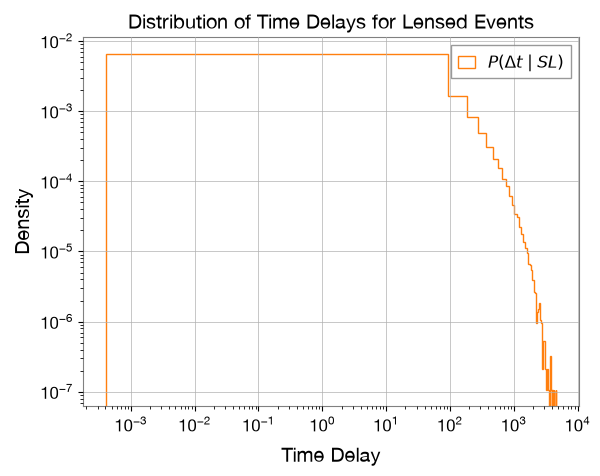

In [60]:
# plot time delay
# covert secs to days
dt = (lensed_pop['effective_geocent_time'][:,1]-lensed_pop['effective_geocent_time'][:,0])/(24*3600)
plt.hist(dt, bins=50, density=True, histtype='step', color='C1', label=r'$P(\Delta t\mid SL)$');
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Time Delay');
plt.ylabel('Density');
plt.title('Distribution of Time Delays for Lensed Events');
plt.legend();
plt.show();